In [491]:
import sys
print(sys.executable)

c:\Users\Lolita\anaconda3\python.exe


In [492]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [493]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data" / "raw"

print("Raw data folder:", RAW_DIR)
print("\nAvailable files:")

for file in RAW_DIR.iterdir():
    print(file.name)

Raw data folder: c:\Users\Lolita\OneDrive\Attachments\NIErnaya\data\raw

Available files:
01_district_crop_production.csv
02_nfhs5_district_nutrition_health.csv
agmarknet_state_monthly.csv.gz
india_districts_simplified.geojson
other_sheets
upag_district_foodgrains.csv.gz
upag_fci_procurement.csv.gz


In [494]:


# Load crop production data
crop_df = pd.read_csv(
    RAW_DIR / "01_district_crop_production.csv"
)

# Load NFHS-5 nutrition data
nfhs_df = pd.read_csv(
    RAW_DIR / "02_nfhs5_district_nutrition_health.csv"
)

# Load UPAG food-grain data
upag_df = pd.read_csv(
    RAW_DIR / "upag_district_foodgrains.csv.gz"
)

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


In [495]:
print("Crop Production:", crop_df.shape)
print("NFHS-5:", nfhs_df.shape)
print("UPAG:", upag_df.shape)


Crop Production: (74242, 8)
NFHS-5: (706, 109)
UPAG: (719427, 7)


In [496]:
print("CROP PRODUCTION COLUMNS")
print(crop_df.columns.tolist())

print("\nNFHS-5 COLUMNS")
print(nfhs_df.columns.tolist())

print("\nUPAG COLUMNS")
print(upag_df.columns.tolist())

CROP PRODUCTION COLUMNS
['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production', 'Yield']

NFHS-5 COLUMNS
['District Names', 'State/UT', 'Number of Households surveyed', 'Number of Women age 15-49 years interviewed', 'Number of Men age 15-54 years interviewed', 'Female population age 6 years and above who ever attended school (%)', 'Population below age 15 years (%)', 'Sex ratio of the total population (females per 1,000 males)', 'Sex ratio at birth for children born in the last five years (females per 1,000 males)', 'Children under age 5 years whose birth was registered with the civil authority (%)', 'Deaths in the last 3 years registered with the civil authority (%)', 'Population living in households with electricity (%)', 'Population living in households with an improved drinking-water source1 (%)', 'Population living in households that use an improved sanitation facility2 (%)', 'Households using clean fuel for cooking3 (%)', 'Households using iodized sal

In [497]:
display(crop_df.head())
display(nfhs_df.head())
display(upag_df.head())

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,Yield
0,Andhra Pradesh,Ananthapuramu,1997,Kharif,Maize,2800.0,4900.0,1.750000
1,Andhra Pradesh,Ananthapuramu,1997,Rabi,Maize,600.0,2400.0,4.000000
2,Andhra Pradesh,Ananthapuramu,1997,Kharif,Rice,35600.0,75400.0,2.117978
3,Andhra Pradesh,Ananthapuramu,1997,Rabi,Rice,18000.0,37300.0,2.072222
4,Andhra Pradesh,Ananthapuramu,1997,Kharif,Sugarcane,700.0,72900.0,104.142857


,District Names,State/UT,Number of Households surveyed,Number of Women age 15-49 years interviewed,Number of Men age 15-54 years interviewed,Female population age 6 years and above who ever attended school (%),Population below age 15 years (%),"Sex ratio of the total population (females per 1,000 males)","Sex ratio at birth for children born in the last five years (females per 1,000 males)",Children under age 5 years whose birth was registered with the civil authority (%),...,Men age 15 years and above wih Mildly elevated blood pressure (Systolic 140-159 mm of Hg and/or Diastolic 90-99 mm of Hg) (%),Men age 15 years and above wih Moderately or severely elevated blood pressure (Systolic ≥160 mm of Hg and/or Diastolic ≥100 mm of Hg) (%),Men age 15 years and above wih Elevated blood pressure (Systolic ≥140 mm of Hg and/or Diastolic ≥90 mm of Hg) or taking medicine to control blood pressure (%),Women (age 30-49 years) Ever undergone a screening test for cervical cancer (%),Women (age 30-49 years) Ever undergone a breast examination for breast cancer (%),Women (age 30-49 years) Ever undergone an oral cavity examination for oral cancer (%),Women age 15 years and above who use any kind of tobacco (%),Men age 15 years and above who use any kind of tobacco (%),Women age 15 years and above who consume alcohol (%),Men age 15 years and above who consume alcohol (%)
0,Nicobars,Andaman & Nicobar Islands,882,764,125,78.0,23.0,973,927,98.0,...,32.9,11.1,47.0,13.4,13.2,5.4,63.5,76.8,29.6,64.5
1,North & Middle Andaman,Andaman & Nicobar Islands,874,789,108,82.7,19.8,950,844,100.0,...,22.6,6.0,32.2,1.7,0.3,15.8,46.8,70.5,5.1,45.3
2,South Andaman,Andaman & Nicobar Islands,868,844,134,84.7,21.0,967,935,96.5,...,17.9,6.1,26.9,1.3,0.7,8.0,19.6,50.8,1.7,32.8
3,Srikakulam,Andhra Pradesh,874,780,100,60.0,20.7,1140,1163,95.0,...,14.4,5.5,22.9,1.0,0.2,3.8,7.1,21.3,0.6,28.3
4,Vizianagaram,Andhra Pradesh,902,853,134,56.0,20.6,1114,898,95.4,...,14.8,6.4,25.1,4.9,0.6,7.3,11.4,21.5,0.8,32.3


,State,District,Crop Year,Season,Crop,Metric,Value
0,Andaman And Nicobar Islands,Nicobars,2015-16,Kharif,Rice,Area,0.0
1,Andaman And Nicobar Islands,Nicobars,2015-16,Kharif,Rice,Yield,2240.0
2,Andaman And Nicobar Islands,Nicobars,2015-16,Kharif,Rice,Production,0.0
3,Andaman And Nicobar Islands,Nicobars,2015-16,Total,Rice,Area,0.0
4,Andaman And Nicobar Islands,Nicobars,2015-16,Total,Rice,Production,0.0


In [498]:
print("CROP DATA")
crop_df.info()

print("\nNFHS DATA")
nfhs_df.info()

print("\nUPAG DATA")
upag_df.info()

CROP DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74242 entries, 0 to 74241
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   State_Name     74242 non-null  object 
 1   District_Name  74242 non-null  object 
 2   Crop_Year      74242 non-null  int64  
 3   Season         74242 non-null  object 
 4   Crop           74242 non-null  object 
 5   Area           74242 non-null  float64
 6   Production     74242 non-null  float64
 7   Yield          74242 non-null  float64
dtypes: float64(3), int64(1), object(4)
memory usage: 4.5+ MB

NFHS DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 706 entries, 0 to 705
Columns: 109 entries, District Names to Men age 15 years and above who consume alcohol (%)
dtypes: float64(54), int64(4), object(51)
memory usage: 601.3+ KB

UPAG DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 719427 entries, 0 to 719426
Data columns (total 7 columns):
 #   Column     Non

In [499]:
print("Missing values in Crop:", crop_df.isnull().sum().sum())
print("Missing values in NFHS:", nfhs_df.isnull().sum().sum())
print("Missing values in UPAG:", upag_df.isnull().sum().sum())

Missing values in Crop: 0
Missing values in NFHS: 0
Missing values in UPAG: 1164


In [500]:
print("CROP DATA")
print(crop_df.isnull().sum())

print("\nNFHS DATA")
print(nfhs_df.isnull().sum().sort_values(ascending=False).head(15))

print("\nUPAG DATA")
print(upag_df.isnull().sum())

CROP DATA
State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
Yield            0
dtype: int64

NFHS DATA
District Names                                                                                                                                               0
Children Prevalence of symptoms of acute respiratory infection (ARI) in the 2 weeks preceding the survey (Children under age 5 years) (%)                    0
Children under 5 years who are underweight (weight-for-age)18 (%)                                                                                            0
Children under 5 years who are severely wasted (weight-for-height)19 (%)                                                                                     0
Children under 5 years who are wasted (weight-for-height)18 (%)                                                                                              0
Children under 5 ye

In [501]:
print("Crop duplicates:", crop_df.duplicated().sum())

print("NFHS duplicates:", nfhs_df.duplicated().sum())

print("UPAG duplicates:", upag_df.duplicated().sum())

Crop duplicates: 0
NFHS duplicates: 0
UPAG duplicates: 0


In [502]:
# Count missing values
crop_df.isnull().sum()

# Remove rows containing missing values
crop_df.dropna()

# Replace missing values
crop_df.fillna(0)

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,Yield
0,Andhra Pradesh,Ananthapuramu,1997,Kharif,Maize,2800.0,4900.0,1.750000
1,Andhra Pradesh,Ananthapuramu,1997,Rabi,Maize,600.0,2400.0,4.000000
2,Andhra Pradesh,Ananthapuramu,1997,Kharif,Rice,35600.0,75400.0,2.117978
3,Andhra Pradesh,Ananthapuramu,1997,Rabi,Rice,18000.0,37300.0,2.072222
4,Andhra Pradesh,Ananthapuramu,1997,Kharif,Sugarcane,700.0,72900.0,104.142857
...,...,...,...,...,...,...,...,...
74237,West Bengal,Uttar Dinajpur,2022,Autumn,Rice,999.0,1990.0,1.991992
74238,West Bengal,Uttar Dinajpur,2022,Summer,Rice,47885.0,149369.0,3.119328
74239,West Bengal,Uttar Dinajpur,2022,Winter,Rice,197826.0,555409.0,2.807563
74240,West Bengal,Uttar Dinajpur,2022,Whole Year,Sugarcane,617.0,51211.0,83.000000


In [503]:
upag_df[upag_df["Value"].isnull()].head(10)

,State,District,Crop Year,Season,Crop,Metric,Value
10542,Chhattisgarh,Bastar,2015-16,Rabi,Lentil,Production,NaN
10543,Chhattisgarh,Bastar,2015-16,Rabi,Lentil,Yield,NaN
10545,Chhattisgarh,Bastar,2015-16,Total,Lentil,Yield,NaN
10547,Chhattisgarh,Bastar,2015-16,Total,Lentil,Production,NaN
11749,Chhattisgarh,Kondagaon,2015-16,Rabi,Lentil,Production,NaN
11750,Chhattisgarh,Kondagaon,2015-16,Rabi,Lentil,Yield,NaN
11752,Chhattisgarh,Kondagaon,2015-16,Total,Lentil,Production,NaN
11753,Chhattisgarh,Kondagaon,2015-16,Total,Lentil,Yield,NaN
11805,Chhattisgarh,Korba,2015-16,Kharif,Bajra,Production,NaN
11806,Chhattisgarh,Korba,2015-16,Kharif,Bajra,Yield,NaN


In [504]:
crop_df[crop_df.duplicated()]

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production,Yield


In [505]:
crop_df = crop_df.drop_duplicates()

In [506]:
upag_df["Crop Year"].dtype

dtype('O')

In [507]:
# Check numerical statistics
crop_df[["Area", "Production", "Yield"]].describe()

,Area,Production,Yield
count,74242.000000,7.424200e+04,74242.000000
mean,30290.682284,1.971704e+05,11.803221
std,55099.139916,9.601693e+05,34.262655
min,0.008000,2.200000e-02,0.001038
25%,415.000000,1.350000e+03,1.518258
50%,4595.000000,1.415081e+04,2.363328
75%,33536.500000,1.087695e+05,3.735000
max,687000.000000,3.715800e+07,2247.533300


In [508]:
print("Zero area:", (crop_df["Area"] == 0).sum())

print("Zero production:", (crop_df["Production"] == 0).sum())

print("Negative area:", (crop_df["Area"] < 0).sum())

print("Negative production:", (crop_df["Production"] < 0).sum())

print("Negative yield:", (crop_df["Yield"] < 0).sum())

Zero area: 0
Zero production: 0
Negative area: 0
Negative production: 0
Negative yield: 0


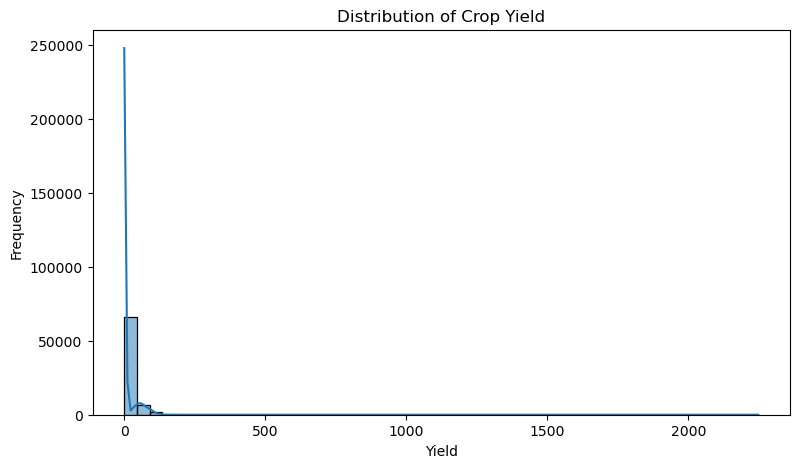

In [509]:
plt.figure(figsize=(9, 5))

sns.histplot(crop_df["Yield"], bins=50, kde=True)

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.show()

In [510]:
crop_df[["Area", "Production", "Yield"]].describe()

,Area,Production,Yield
count,74242.000000,7.424200e+04,74242.000000
mean,30290.682284,1.971704e+05,11.803221
std,55099.139916,9.601693e+05,34.262655
min,0.008000,2.200000e-02,0.001038
25%,415.000000,1.350000e+03,1.518258
50%,4595.000000,1.415081e+04,2.363328
75%,33536.500000,1.087695e+05,3.735000
max,687000.000000,3.715800e+07,2247.533300


In [511]:
crop_df.nlargest(10, "Yield")[
    ["State_Name", "District_Name", "Crop_Year",
     "Crop", "Area", "Production", "Yield"]
]

,State_Name,District_Name,Crop_Year,Crop,Area,Production,Yield
1567,Tamil Nadu,Madurai,1997,Sugarcane,8108.0,18223000.0,2247.533300
1596,Tamil Nadu,Thiruvallur,1997,Sugarcane,5964.0,11811000.0,1980.382294
1143,Maharashtra,Nashik,1997,Maize,1.0,1494.0,1494.000000
1561,Tamil Nadu,Kancheepuram,1997,Sugarcane,6735.0,9896000.0,1469.339272
1573,Tamil Nadu,Namakkal,1997,Sugarcane,9415.0,13608000.0,1445.353160
1605,Tamil Nadu,Tiruchirappalli,1997,Sugarcane,4315.0,5806000.0,1345.538818
1107,Maharashtra,Jalgaon,1997,Maize,3.0,3980.0,1326.666667
1548,Tamil Nadu,Cuddalore,1997,Sugarcane,23826.0,28322000.0,1188.701419
1564,Tamil Nadu,Karur,1997,Sugarcane,5961.0,7081000.0,1187.887938
1584,Tamil Nadu,Salem,1997,Sugarcane,13759.0,15866000.0,1153.136129


In [512]:
calculated_yield = crop_df["Production"] / crop_df["Area"]

difference = (crop_df["Yield"] - calculated_yield).abs()

print("Records with yield discrepancies:", (difference > 0.01).sum())

Records with yield discrepancies: 0


In [513]:
crop_df.nlargest(10, "Yield")[
    ["State_Name", "District_Name", "Crop_Year",
     "Crop", "Area", "Production", "Yield"]
]

,State_Name,District_Name,Crop_Year,Crop,Area,Production,Yield
1567,Tamil Nadu,Madurai,1997,Sugarcane,8108.0,18223000.0,2247.533300
1596,Tamil Nadu,Thiruvallur,1997,Sugarcane,5964.0,11811000.0,1980.382294
1143,Maharashtra,Nashik,1997,Maize,1.0,1494.0,1494.000000
1561,Tamil Nadu,Kancheepuram,1997,Sugarcane,6735.0,9896000.0,1469.339272
1573,Tamil Nadu,Namakkal,1997,Sugarcane,9415.0,13608000.0,1445.353160
1605,Tamil Nadu,Tiruchirappalli,1997,Sugarcane,4315.0,5806000.0,1345.538818
1107,Maharashtra,Jalgaon,1997,Maize,3.0,3980.0,1326.666667
1548,Tamil Nadu,Cuddalore,1997,Sugarcane,23826.0,28322000.0,1188.701419
1564,Tamil Nadu,Karur,1997,Sugarcane,5961.0,7081000.0,1187.887938
1584,Tamil Nadu,Salem,1997,Sugarcane,13759.0,15866000.0,1153.136129


In [514]:
crop_df.groupby("Crop")["Yield"].describe()

,count,mean,std,min,25%,50%,75%,max
Crop,,,,,,,,
Maize,24055.0,2.743886,18.644195,0.001282,1.392445,2.000252,3.000000,1494.000000
Rice,25024.0,2.189106,1.765290,0.002002,1.430418,2.128375,2.813999,223.727273
Sugarcane,12321.0,58.933401,61.024751,0.001038,37.209573,56.400000,76.614409,2247.533300
Wheat,12842.0,2.288733,1.138892,0.046255,1.376083,2.071882,3.039621,7.461538


In [515]:
crop_df["Crop"].value_counts()

Crop
Rice         25024
Maize        24055
Wheat        12842
Sugarcane    12321
Name: count, dtype: int64

In [516]:
crop_summary = (
    crop_df.groupby("Crop")["Production"]
    .sum()
    .sort_values(ascending=False)
)

display(crop_summary)

Crop
Sugarcane    9.013055e+09
Rice         2.683186e+09
Wheat        2.388639e+09
Maize        5.534440e+08
Name: Production, dtype: float64

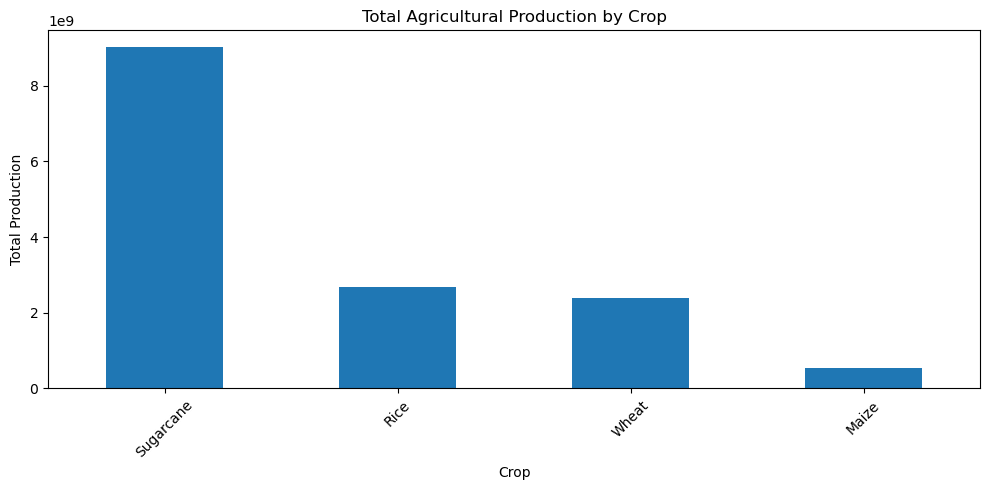

In [517]:
plt.figure(figsize=(10, 5))

crop_summary.plot(kind="bar")

plt.title("Total Agricultural Production by Crop")
plt.xlabel("Crop")
plt.ylabel("Total Production")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [518]:
state_yield = (
    crop_df.groupby(["State_Name", "Crop"])["Yield"]
    .mean()
    .reset_index()
)

display(state_yield.head(10))

,State_Name,Crop,Yield
0,Andaman And Nicobar Islands,Maize,2.379882
1,Andaman And Nicobar Islands,Rice,2.328036
2,Andaman And Nicobar Islands,Sugarcane,13.909116
3,Andhra Pradesh,Maize,5.014134
4,Andhra Pradesh,Rice,3.117610
5,Andhra Pradesh,Sugarcane,82.348921
6,Andhra Pradesh,Wheat,0.853116
7,Arunachal Pradesh,Maize,1.379618
8,Arunachal Pradesh,Rice,1.424876
9,Arunachal Pradesh,Sugarcane,20.109679


In [519]:
rice_yield = state_yield[
    state_yield["Crop"] == "Rice"
].sort_values("Yield", ascending=False)

display(rice_yield.head(10))

,State_Name,Crop,Yield
20,Chandigarh,Rice,5.002000
89,Punjab,Rice,3.849385
26,Goa,Rice,3.815809
100,Tamil Nadu,Rice,3.769670
4,Andhra Pradesh,Rice,3.117610
104,Telangana,Rice,3.095238
33,Haryana,Rice,2.871336
49,Karnataka,Rice,2.666110
86,Puducherry,Rice,2.630945
124,West Bengal,Rice,2.583314


In [520]:
for col in nfhs_df.columns:
    if any(word in col.lower() for word in
           ["stunted", "wasted", "underweight"]):
        print(col)

Children under 5 years who are stunted (height-for-age)18 (%)
Children under 5 years who are wasted (weight-for-height)18 (%)
Children under 5 years who are severely wasted (weight-for-height)19 (%)
Children under 5 years who are underweight (weight-for-age)18 (%)


In [521]:
#| Indicator | Meaning |
#|---|---|
#| Stunting | Low height-for-age; reflects chronic undernutrition |
#| Wasting | Low weight-for-height; reflects acute undernutrition |
#| Underweight | Low weight-for-age |


In [522]:
for col in nfhs_df.columns:
    if "stunted" in col.lower():
        print(repr(col))

'Children under 5 years who are stunted (height-for-age)18 (%)'


In [523]:
for col in nfhs_df.columns:
    if any(word in col.lower() for word in
           ["stunted", "wasted", "underweight"]):
        print(col)

Children under 5 years who are stunted (height-for-age)18 (%)
Children under 5 years who are wasted (weight-for-height)18 (%)
Children under 5 years who are severely wasted (weight-for-height)19 (%)
Children under 5 years who are underweight (weight-for-age)18 (%)


In [524]:
nutrition_cols = [
    "Children under 5 years who are stunted (height-for-age)18 (%)",
    "Children under 5 years who are wasted (weight-for-height)18 (%)",
    "Children under 5 years who are severely wasted (weight-for-height)19 (%)",
    "Children under 5 years who are underweight (weight-for-age)18 (%)"
]

nfhs_df[nutrition_cols].describe().T

,count,unique,top,freq
Children under 5 years who are stunted (height-for-age)18 (%),706,304,27.1,9
Children under 5 years who are wasted (weight-for-height)18 (%),706,240,18.2,10
Children under 5 years who are severely wasted (weight-for-height)19 (%),706,162,4.3,15
Children under 5 years who are underweight (weight-for-age)18 (%),706,325,32.3,7


In [525]:
nfhs_df[nutrition_cols].dtypes

Children under 5 years who are stunted (height-for-age)18 (%)               object
Children under 5 years who are wasted (weight-for-height)18 (%)             object
Children under 5 years who are severely wasted (weight-for-height)19 (%)    object
Children under 5 years who are underweight (weight-for-age)18 (%)           object
dtype: object

In [526]:
for col in nutrition_cols:
    nfhs_df[col] = pd.to_numeric(nfhs_df[col], errors="coerce")

In [527]:
print(nfhs_df[nutrition_cols].dtypes)

print("\nMissing values after conversion:")
print(nfhs_df[nutrition_cols].isnull().sum())

Children under 5 years who are stunted (height-for-age)18 (%)               float64
Children under 5 years who are wasted (weight-for-height)18 (%)             float64
Children under 5 years who are severely wasted (weight-for-height)19 (%)    float64
Children under 5 years who are underweight (weight-for-age)18 (%)           float64
dtype: object

Missing values after conversion:
Children under 5 years who are stunted (height-for-age)18 (%)               1
Children under 5 years who are wasted (weight-for-height)18 (%)             1
Children under 5 years who are severely wasted (weight-for-height)19 (%)    1
Children under 5 years who are underweight (weight-for-age)18 (%)           1
dtype: int64


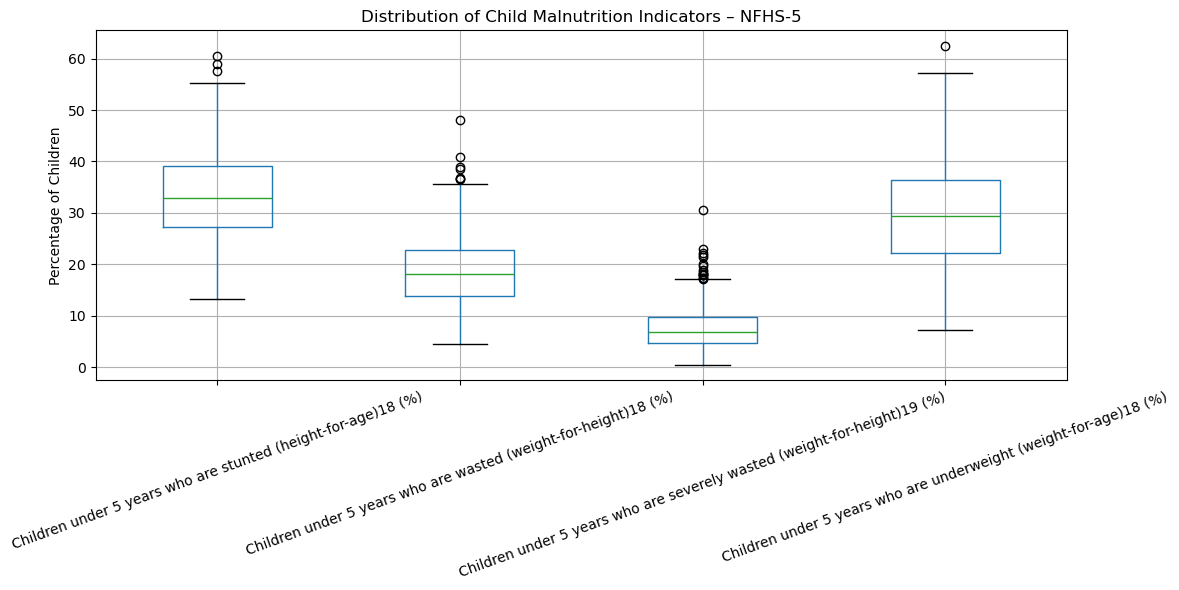

In [528]:
plt.figure(figsize=(12, 6))

nfhs_df[nutrition_cols].boxplot()

plt.title("Distribution of Child Malnutrition Indicators – NFHS-5")
plt.ylabel("Percentage of Children")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [529]:
'''| Component | Meaning |
|---|---|
| Green line | Median |
| Box | Middle 50% of observations (25th–75th percentile) |
| Whiskers | Range of non-outlier observations |
| Circles | Potential outliers |'''

'| Component | Meaning |\n|---|---|\n| Green line | Median |\n| Box | Middle 50% of observations (25th–75th percentile) |\n| Whiskers | Range of non-outlier observations |\n| Circles | Potential outliers |'

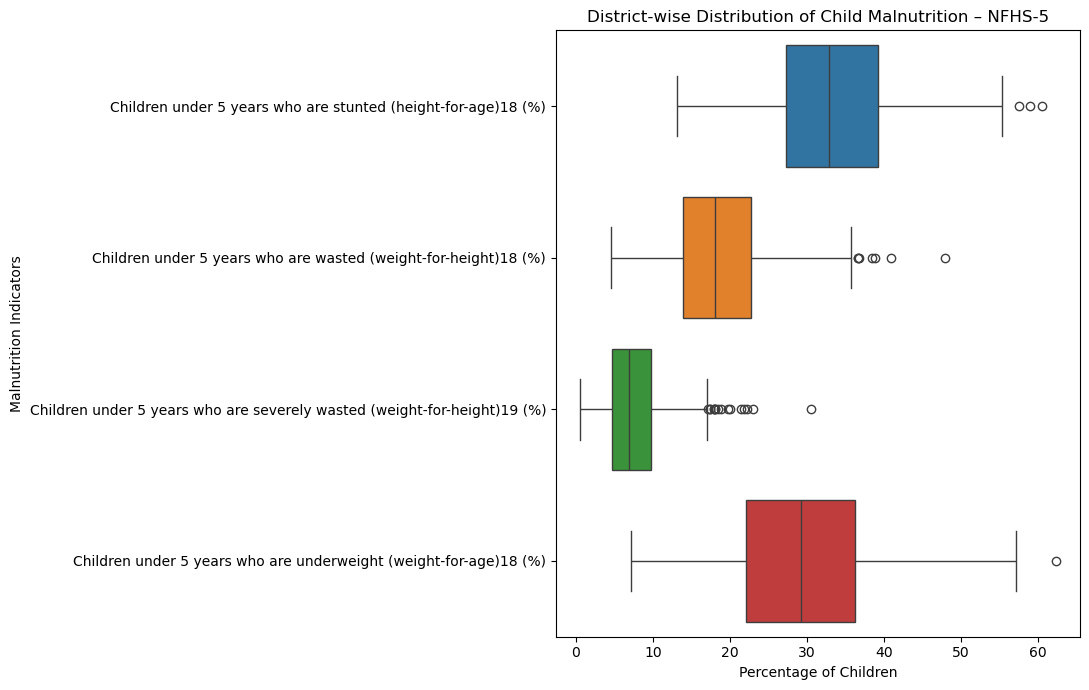

In [530]:
plt.figure(figsize=(11, 7))

sns.boxplot(
    data=nfhs_df[nutrition_cols],
    orient="h"
)

plt.title("District-wise Distribution of Child Malnutrition – NFHS-5")
plt.xlabel("Percentage of Children")
plt.ylabel("Malnutrition Indicators")

plt.tight_layout()
plt.show()

In [531]:
'''| Indicator | Approx. median | Observation |
|---|---:|---|
| Stunting | 33% | Highest median among the four indicators |
| Wasting | 18% | Moderate district-level variation |
| Severe wasting | 7% | Lower median, with several high outliers |
| Underweight | 29.5% | Substantial variation across districts |'''

'| Indicator | Approx. median | Observation |\n|---|---:|---|\n| Stunting | 33% | Highest median among the four indicators |\n| Wasting | 18% | Moderate district-level variation |\n| Severe wasting | 7% | Lower median, with several high outliers |\n| Underweight | 29.5% | Substantial variation across districts |'

In [532]:
#Data integration means combining information from multiple datasets into one unified dataset.

In [533]:
print("Minimum year:", crop_df["Crop_Year"].min())
print("Maximum year:", crop_df["Crop_Year"].max())

print("\nAvailable crops:")
print(crop_df["Crop"].unique())

Minimum year: 1997
Maximum year: 2022

Available crops:
['Maize' 'Rice' 'Sugarcane' 'Wheat']


In [534]:
crop_recent = crop_df[
    (crop_df["Crop_Year"] >= 2017) &
    (crop_df["Crop_Year"] <= 2021)
].copy()

print("Original records:", len(crop_df))
print("Recent records:", len(crop_recent))

Original records: 74242
Recent records: 16491


In [535]:
selected_crops = ["Rice", "Wheat", "Maize"]

crop_selected = crop_recent[
    crop_recent["Crop"].isin(selected_crops)
].copy()

district_crop_summary = (
    crop_selected
    .groupby(["State_Name", "District_Name", "Crop"])["Yield"]
    .mean()
    .reset_index()
)

display(district_crop_summary.head(10))

,State_Name,District_Name,Crop,Yield
0,Andaman And Nicobar Islands,Nicobars,Maize,1.133333
1,Andaman And Nicobar Islands,Nicobars,Rice,1.127650
2,Andaman And Nicobar Islands,North And Middle Andaman,Maize,2.305821
3,Andaman And Nicobar Islands,North And Middle Andaman,Rice,2.459002
4,Andaman And Nicobar Islands,South Andamans,Maize,1.626599
5,Andaman And Nicobar Islands,South Andamans,Rice,2.477681
6,Andhra Pradesh,Ananthapuramu,Maize,3.778496
7,Andhra Pradesh,Ananthapuramu,Rice,2.795397
8,Andhra Pradesh,Ananthapuramu,Wheat,0.875595
9,Andhra Pradesh,Chittoor,Maize,3.954843


In [536]:
crop_wide = district_crop_summary.pivot_table(
    index=["State_Name", "District_Name"],
    columns="Crop",
    values="Yield"
).reset_index()

crop_wide.columns.name = None

display(crop_wide.head(10))

,State_Name,District_Name,Maize,Rice,Wheat
0,Andaman And Nicobar Islands,Nicobars,1.133333,1.127650,NaN
1,Andaman And Nicobar Islands,North And Middle Andaman,2.305821,2.459002,NaN
2,Andaman And Nicobar Islands,South Andamans,1.626599,2.477681,NaN
3,Andhra Pradesh,Ananthapuramu,3.778496,2.795397,0.875595
4,Andhra Pradesh,Chittoor,3.954843,3.658895,NaN
5,Andhra Pradesh,East Godavari,6.320730,4.126117,NaN
6,Andhra Pradesh,Guntur,7.388467,3.826630,1.333333
7,Andhra Pradesh,Krishna,5.373801,4.027235,NaN
8,Andhra Pradesh,Kurnool,4.807599,3.616257,0.849270
9,Andhra Pradesh,Prakasam,5.007895,3.539768,2.000000


In [537]:
print(nfhs_df.columns[:5].tolist())

['District Names', 'State/UT', 'Number of Households surveyed', 'Number of Women age 15-49 years interviewed', 'Number of Men age 15-54 years interviewed']


In [538]:
nutrition_df = nfhs_df[
    [
        "District Names",
        "State/UT",
        "Children under 5 years who are stunted (height-for-age)18 (%)",
        "Children under 5 years who are wasted (weight-for-height)18 (%)",
        "Children under 5 years who are underweight (weight-for-age)18 (%)"
    ]
].copy()

In [539]:
nutrition_df = nutrition_df.rename(columns={
    "District Names": "District_Name",
    "State/UT": "State_Name",
    "Children under 5 years who are stunted (height-for-age)18 (%)": "Stunting",
    "Children under 5 years who are wasted (weight-for-height)18 (%)": "Wasting",
    "Children under 5 years who are underweight (weight-for-age)18 (%)": "Underweight"
})

display(nutrition_df.head())

,District_Name,State_Name,Stunting,Wasting,Underweight
0,Nicobars,Andaman & Nicobar Islands,21.6,15.7,24.6
1,North & Middle Andaman,Andaman & Nicobar Islands,27.0,27.0,42.8
2,South Andaman,Andaman & Nicobar Islands,21.1,12.6,17.4
3,Srikakulam,Andhra Pradesh,19.7,19.5,21.4
4,Vizianagaram,Andhra Pradesh,36.4,19.2,32.2


In [540]:
def normalise_name(name):
    return (
        str(name)
        .strip()
        .lower()
        .replace("&", "and")
        .replace(" ", "")
    )

In [541]:
crop_wide["district_key"] = crop_wide["District_Name"].apply(normalise_name)
nutrition_df["district_key"] = nutrition_df["District_Name"].apply(normalise_name)

crop_wide["state_key"] = crop_wide["State_Name"].apply(normalise_name)
nutrition_df["state_key"] = nutrition_df["State_Name"].apply(normalise_name)

In [542]:
crop_keys = set(
    zip(crop_wide["state_key"], crop_wide["district_key"])
)

nutrition_keys = set(
    zip(nutrition_df["state_key"], nutrition_df["district_key"])
)

matched = crop_keys.intersection(nutrition_keys)

print("Agricultural districts:", len(crop_keys))
print("NFHS districts:", len(nutrition_keys))
print("Matched districts:", len(matched))
print("Unmatched agricultural districts:", len(crop_keys - nutrition_keys))
print("Unmatched NFHS districts:", len(nutrition_keys - crop_keys))

Agricultural districts: 710
NFHS districts: 706
Matched districts: 562
Unmatched agricultural districts: 148
Unmatched NFHS districts: 144


In [543]:
print("Crop duplicate district keys:",
      crop_wide.duplicated(["state_key", "district_key"]).sum())

print("NFHS duplicate district keys:",
      nutrition_df.duplicated(["state_key", "district_key"]).sum())

Crop duplicate district keys: 0
NFHS duplicate district keys: 0


In [544]:
integrated_df = pd.merge(
    crop_wide,
    nutrition_df,
    on=["state_key", "district_key"],
    how="inner",
    validate="one_to_one"
)

print("Integrated dataset shape:", integrated_df.shape)

display(integrated_df.head())

Integrated dataset shape: (562, 12)


,State_Name_x,District_Name_x,Maize,Rice,Wheat,district_key,state_key,District_Name_y,State_Name_y,Stunting,Wasting,Underweight
0,Andaman And Nicobar Islands,Nicobars,1.133333,1.127650,NaN,nicobars,andamanandnicobarislands,Nicobars,Andaman & Nicobar Islands,21.6,15.7,24.6
1,Andaman And Nicobar Islands,North And Middle Andaman,2.305821,2.459002,NaN,northandmiddleandaman,andamanandnicobarislands,North & Middle Andaman,Andaman & Nicobar Islands,27.0,27.0,42.8
2,Andhra Pradesh,Chittoor,3.954843,3.658895,NaN,chittoor,andhrapradesh,Chittoor,Andhra Pradesh,27.1,14.8,27.9
3,Andhra Pradesh,East Godavari,6.320730,4.126117,NaN,eastgodavari,andhrapradesh,East Godavari,Andhra Pradesh,23.1,14.3,22.4
4,Andhra Pradesh,Guntur,7.388467,3.826630,1.333333,guntur,andhrapradesh,Guntur,Andhra Pradesh,23.8,17.8,26.9


In [545]:
print("Total districts:", len(integrated_df))

print("\nMissing values:")
print(integrated_df.isnull().sum())

print("\nDuplicate records:", integrated_df.duplicated().sum())

Total districts: 562

Missing values:
State_Name_x        0
District_Name_x     0
Maize              15
Rice               19
Wheat              97
district_key        0
state_key           0
District_Name_y     0
State_Name_y        0
Stunting            1
Wasting             1
Underweight         1
dtype: int64

Duplicate records: 0


In [546]:
print(integrated_df.columns.tolist())

['State_Name_x', 'District_Name_x', 'Maize', 'Rice', 'Wheat', 'district_key', 'state_key', 'District_Name_y', 'State_Name_y', 'Stunting', 'Wasting', 'Underweight']


In [547]:
'''| Python/Pandas operation | Application |
|---|---|
| `read_csv()` | Loading datasets |
| `groupby()` | Calculating district-level averages |
| `pivot_table()` | Converting long data into wide format |
| `rename()` | Renaming columns |
| `apply()` | Applying text normalisation |
| `merge()` | Integrating datasets |
| `duplicated()` | Detecting duplicate records |
| `to_csv()` | Exporting processed data |'''

'| Python/Pandas operation | Application |\n|---|---|\n| `read_csv()` | Loading datasets |\n| `groupby()` | Calculating district-level averages |\n| `pivot_table()` | Converting long data into wide format |\n| `rename()` | Renaming columns |\n| `apply()` | Applying text normalisation |\n| `merge()` | Integrating datasets |\n| `duplicated()` | Detecting duplicate records |\n| `to_csv()` | Exporting processed data |'

In [548]:
#Our research question is:

#Does higher agricultural productivity necessarily correspond to lower child malnutrition?

In [549]:
print(integrated_df.shape)
print(integrated_df.columns.tolist())

(562, 12)
['State_Name_x', 'District_Name_x', 'Maize', 'Rice', 'Wheat', 'district_key', 'state_key', 'District_Name_y', 'State_Name_y', 'Stunting', 'Wasting', 'Underweight']


In [550]:
agriculture_cols = ["Rice", "Wheat", "Maize"]

nutrition_cols = [
    "Stunting",
    "Wasting",
    "Underweight"
]

In [551]:
#Calculate the Pearson correlation matrix:
correlation_df = integrated_df[
    agriculture_cols + nutrition_cols
].corr(method="pearson")

display(correlation_df)

,Rice,Wheat,Maize,Stunting,Wasting,Underweight
Rice,1.000000,0.337026,0.495573,-0.210404,-0.108525,-0.125618
Wheat,0.337026,1.000000,-0.056777,-0.113418,-0.136862,-0.112453
Maize,0.495573,-0.056777,1.000000,-0.124833,0.007293,0.002193
Stunting,-0.210404,-0.113418,-0.124833,1.000000,0.277755,0.717790
Wasting,-0.108525,-0.136862,0.007293,0.277755,1.000000,0.716133
Underweight,-0.125618,-0.112453,0.002193,0.717790,0.716133,1.000000


In [552]:
'''If Rice and Stunting have a correlation of -0.35, 
it suggests that districts 
with higher rice yield tend to have
lower stunting, although the relationship
is not necessarily strong.'''

'If Rice and Stunting have a correlation of -0.35, \nit suggests that districts \nwith higher rice yield tend to have\nlower stunting, although the relationship\nis not necessarily strong.'

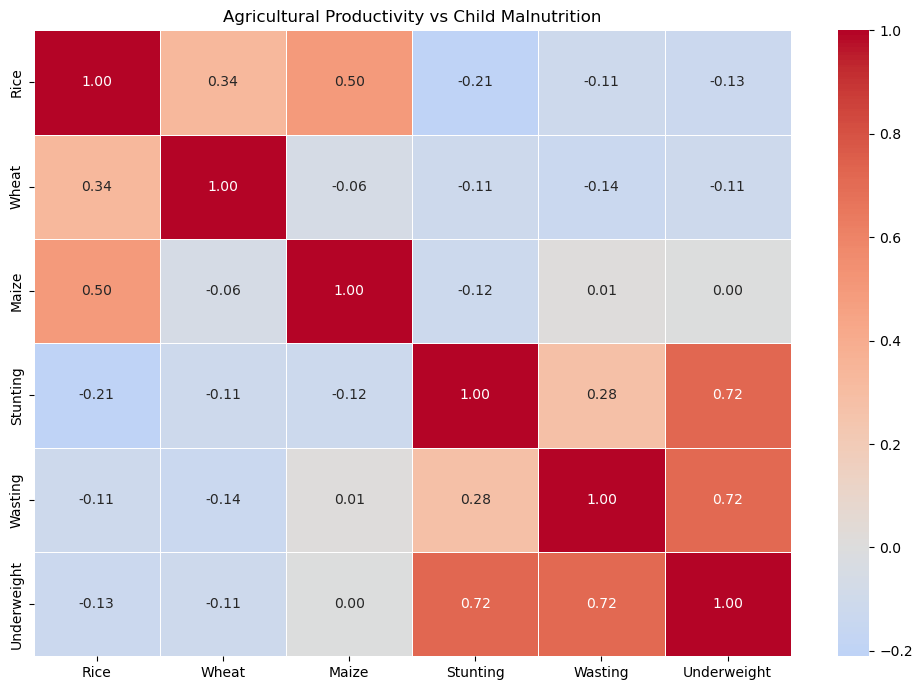

In [553]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Agricultural Productivity vs Child Malnutrition")
plt.tight_layout()
plt.show()

In [554]:
pearson_corr = integrated_df[
    agriculture_cols + nutrition_cols
].corr(method="pearson")

spearman_corr = integrated_df[
    agriculture_cols + nutrition_cols
].corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr)

print("SPEARMAN CORRELATION")
display(spearman_corr)

PEARSON CORRELATION


,Rice,Wheat,Maize,Stunting,Wasting,Underweight
Rice,1.000000,0.337026,0.495573,-0.210404,-0.108525,-0.125618
Wheat,0.337026,1.000000,-0.056777,-0.113418,-0.136862,-0.112453
Maize,0.495573,-0.056777,1.000000,-0.124833,0.007293,0.002193
Stunting,-0.210404,-0.113418,-0.124833,1.000000,0.277755,0.717790
Wasting,-0.108525,-0.136862,0.007293,0.277755,1.000000,0.716133
Underweight,-0.125618,-0.112453,0.002193,0.717790,0.716133,1.000000


SPEARMAN CORRELATION


,Rice,Wheat,Maize,Stunting,Wasting,Underweight
Rice,1.000000,0.311486,0.427537,-0.169975,-0.086964,-0.093038
Wheat,0.311486,1.000000,0.018696,-0.080546,-0.108489,-0.076168
Maize,0.427537,0.018696,1.000000,-0.044082,0.023591,0.066740
Stunting,-0.169975,-0.080546,-0.044082,1.000000,0.300205,0.733423
Wasting,-0.086964,-0.108489,0.023591,0.300205,1.000000,0.708124
Underweight,-0.093038,-0.076168,0.066740,0.733423,0.708124,1.000000


In [555]:
'''| Pearson | Spearman |
|---|---|
| Measures linear relationships | Measures monotonic relationships |
| Uses actual numerical values | Uses ranked values |
| Sensitive to extreme values | Less sensitive to extreme values |
| Assumes a linear association for interpretation | Does not require linearity |'''

'| Pearson | Spearman |\n|---|---|\n| Measures linear relationships | Measures monotonic relationships |\n| Uses actual numerical values | Uses ranked values |\n| Sensitive to extreme values | Less sensitive to extreme values |\n| Assumes a linear association for interpretation | Does not require linearity |'

In [556]:
'''Generally:
- p-value < 0.05: statistically significant evidence of an association.
- p-value ≥ 0.05: insufficient evidence to reject the null hypothesis.'''

'Generally:\n- p-value < 0.05: statistically significant evidence of an association.\n- p-value ≥ 0.05: insufficient evidence to reject the null hypothesis.'

In [557]:
from scipy.stats import pearsonr, spearmanr

for crop in agriculture_cols:
    for nutrition in nutrition_cols:

        temp = integrated_df[[crop, nutrition]].dropna()

        if len(temp) < 3:
            continue

        r, p = pearsonr(
            temp[crop],
            temp[nutrition]
        )

        print(f"\n{crop} vs {nutrition}")
        print("Pearson correlation:", round(r, 3))
        print("P-value:", round(p, 4))
        print("Districts:", len(temp))


Rice vs Stunting
Pearson correlation: -0.21
P-value: 0.0
Districts: 542

Rice vs Wasting
Pearson correlation: -0.109
P-value: 0.0115
Districts: 542

Rice vs Underweight
Pearson correlation: -0.126
P-value: 0.0034
Districts: 542

Wheat vs Stunting
Pearson correlation: -0.113
P-value: 0.0145
Districts: 464

Wheat vs Wasting
Pearson correlation: -0.137
P-value: 0.0031
Districts: 464

Wheat vs Underweight
Pearson correlation: -0.112
P-value: 0.0154
Districts: 464

Maize vs Stunting
Pearson correlation: -0.125
P-value: 0.0035
Districts: 546

Maize vs Wasting
Pearson correlation: 0.007
P-value: 0.865
Districts: 546

Maize vs Underweight
Pearson correlation: 0.002
P-value: 0.9592
Districts: 546


In [558]:
'''What does this mean?
Take rice yield versus stunting.

Your correlation is:
\[
r=-0.21
\]
This means there is a weak negative linear association.

In general, districts with higher rice yield tend to have somewhat lower stunting, but the relationship is weak.'''

'What does this mean?\nTake rice yield versus stunting.\n\nYour correlation is:\n\\[\nr=-0.21\n\\]\nThis means there is a weak negative linear association.\n\nIn general, districts with higher rice yield tend to have somewhat lower stunting, but the relationship is weak.'

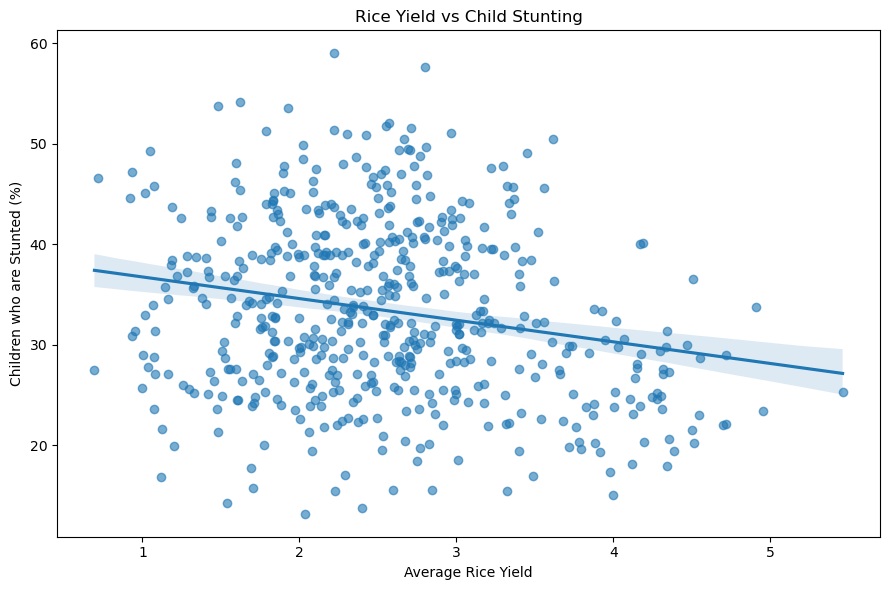

In [559]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=integrated_df,
    x="Rice",
    y="Stunting",
    scatter_kws={"alpha": 0.6}
)

plt.title("Rice Yield vs Child Stunting")
plt.xlabel("Average Rice Yield")
plt.ylabel("Children who are Stunted (%)")

plt.tight_layout()
plt.show()

In [560]:
'''If agricultural yield alone explained child stunting, we would expect the points to follow a much clearer downward pattern.

Instead, the points are widely scattered.

This suggests that other factors may also be important.'''

'If agricultural yield alone explained child stunting, we would expect the points to follow a much clearer downward pattern.\n\nInstead, the points are widely scattered.\n\nThis suggests that other factors may also be important.'

In [561]:
from scipy.stats import pearsonr

temp = integrated_df[["Rice", "Stunting"]].dropna()

r, p = pearsonr(temp["Rice"], temp["Stunting"])

print(f"Correlation: {r:.4f}")
print(f"P-value: {p:.10f}")

Correlation: -0.2104
P-value: 0.0000007712


In [562]:
'''A p-value below 0.05 indicates statistically 
significant evidence against the null hypothesis of zero 
linear correlation, under the test's assumptions.'''

"A p-value below 0.05 indicates statistically \nsignificant evidence against the null hypothesis of zero \nlinear correlation, under the test's assumptions."

In [563]:
'''Higher rice yield is associated with somewhat lower stunting.
The association is weak.
Wheat and maize also show generally weak associations with malnutrition.
Agricultural productivity alone does not explain the variation in nutritional outcomes.'''

'Higher rice yield is associated with somewhat lower stunting.\nThe association is weak.\nWheat and maize also show generally weak associations with malnutrition.\nAgricultural productivity alone does not explain the variation in nutritional outcomes.'

In [564]:
'''| Category | Agricultural productivity | Malnutrition |
|---|---|---|
| 1 | High | Low |
| 2 | High | High |
| 3 | Low | High |
| 4 | Low | Low |'''

'| Category | Agricultural productivity | Malnutrition |\n|---|---|---|\n| 1 | High | Low |\n| 2 | High | High |\n| 3 | Low | High |\n| 4 | Low | Low |'

In [565]:
rice_threshold = integrated_df["Rice"].quantile(0.67)

stunting_threshold = integrated_df["Stunting"].quantile(0.67)

print("High rice yield threshold:", rice_threshold)
print("High stunting threshold:", stunting_threshold)

High rice yield threshold: 2.7991672603288964
High stunting threshold: 37.52


In [566]:
integrated_df["Agriculture_Level"] = np.where(
    integrated_df["Rice"] >= rice_threshold,
    "High",
    "Low"
)

integrated_df["Malnutrition_Level"] = np.where(
    integrated_df["Stunting"] >= stunting_threshold,
    "High",
    "Low"
)

In [567]:
category_counts = pd.crosstab(
    integrated_df["Agriculture_Level"],
    integrated_df["Malnutrition_Level"]
)

display(category_counts)

Malnutrition_Level,High,Low
Agriculture_Level,,
High,44,135
Low,141,242


In [568]:
#Multi-dimensional Analysis

In [569]:
'''Socioeconomic Factors Analysis
Your NFHS-5 dataset contains 109 columns. Many of these describe household and social conditions.

We'll investigate four important dimensions:
1. Women's education.
2. Household sanitation.
3. Household cooking fuel.
4. Household wealth.
These factors can help us investigate nutritional disparities beyond agricultural productivity.'''

"Socioeconomic Factors Analysis\nYour NFHS-5 dataset contains 109 columns. Many of these describe household and social conditions.\n\nWe'll investigate four important dimensions:\n1. Women's education.\n2. Household sanitation.\n3. Household cooking fuel.\n4. Household wealth.\nThese factors can help us investigate nutritional disparities beyond agricultural productivity."

In [570]:
keywords = [
    "school",
    "sanitation",
    "toilet",
    "fuel",
    "wealth",
    "electricity",
    "drinking water"
]

for keyword in keywords:
    print(f"\n--- {keyword.upper()} ---")

    for col in nfhs_df.columns:
        if keyword in col.lower():
            print(col)


--- SCHOOL ---
Female population age 6 years and above who ever attended school (%)
Children age 5 years who attended pre-primary school during the school year 2019-20 (%)
Women (age 15-49)  with 10 or more years of schooling (%)

--- SANITATION ---
Population living in households that use an improved sanitation facility2 (%)

--- TOILET ---

--- FUEL ---
Households using clean fuel for cooking3 (%)

--- WEALTH ---

--- ELECTRICITY ---
Population living in households with electricity (%)

--- DRINKING WATER ---


In [571]:
'''| Factor | Potential relationship with nutrition |
|---|---|
| Women's education | Can influence nutrition knowledge and healthcare decisions. |
| Sanitation | Poor sanitation can increase exposure to infections. |
| Cooking fuel | Household fuel conditions can reflect socioeconomic disadvantage and affect indoor air quality. |
| Wealth | Household economic conditions influence food affordability and access to healthcare. |'''

"| Factor | Potential relationship with nutrition |\n|---|---|\n| Women's education | Can influence nutrition knowledge and healthcare decisions. |\n| Sanitation | Poor sanitation can increase exposure to infections. |\n| Cooking fuel | Household fuel conditions can reflect socioeconomic disadvantage and affect indoor air quality. |\n| Wealth | Household economic conditions influence food affordability and access to healthcare. |"

In [572]:
nfhs_df[[
    "District Names",
    "State/UT",
    "Female population age 6 years and above who ever attended school (%)"
]].head()

,District Names,State/UT,Female population age 6 years and above who ever attended school (%)
0,Nicobars,Andaman & Nicobar Islands,78.0
1,North & Middle Andaman,Andaman & Nicobar Islands,82.7
2,South Andaman,Andaman & Nicobar Islands,84.7
3,Srikakulam,Andhra Pradesh,60.0
4,Vizianagaram,Andhra Pradesh,56.0


In [573]:
socio_cols = [
    "District Names",
    "State/UT",
    "Women (age 15-49)  with 10 or more years of schooling (%)",
    "Population living in households that use an improved sanitation facility2 (%)",
    "Households using clean fuel for cooking3 (%)",
    "Population living in households with electricity (%)"
]

socio_df = nfhs_df[socio_cols].copy()

display(socio_df.head())

,District Names,State/UT,Women (age 15-49) with 10 or more years of schooling (%),Population living in households that use an improved sanitation facility2 (%),Households using clean fuel for cooking3 (%),Population living in households with electricity (%)
0,Nicobars,Andaman & Nicobar Islands,53.5,83.5,56.9,97.9
1,North & Middle Andaman,Andaman & Nicobar Islands,41.0,86.4,61.3,93.2
2,South Andaman,Andaman & Nicobar Islands,57.5,89.3,91.9,99.6
3,Srikakulam,Andhra Pradesh,42.5,71.6,74.7,99.9
4,Vizianagaram,Andhra Pradesh,37.6,61.7,60.3,99.5


In [574]:
socio_df = socio_df.rename(columns={
    "District Names": "District_Name",
    "State/UT": "State_Name",
    "Women (age 15-49)  with 10 or more years of schooling (%)": "Women_Education",
    "Population living in households that use an improved sanitation facility2 (%)": "Sanitation",
    "Households using clean fuel for cooking3 (%)": "Clean_Fuel",
    "Population living in households with electricity (%)": "Electricity"
})

In [575]:
socio_df["district_key"] = socio_df["District_Name"].apply(normalise_name)
socio_df["state_key"] = socio_df["State_Name"].apply(normalise_name)

integrated_df = pd.merge(
    integrated_df,
    socio_df[
        [
            "state_key",
            "district_key",
            "Women_Education",
            "Sanitation",
            "Clean_Fuel",
            "Electricity"
        ]
    ],
    on=["state_key", "district_key"],
    how="left",
    validate="one_to_one"
)

print("Updated dataset:", integrated_df.shape)

Updated dataset: (562, 18)


In [576]:
socio_analysis_cols = [
    "Stunting",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

socio_corr = integrated_df[socio_analysis_cols].corr(
    method="pearson"
)

display(socio_corr)

,Stunting,Women_Education,Sanitation,Clean_Fuel,Electricity
Stunting,1.000000,-0.568907,-0.522143,-0.442874,-0.424610
Women_Education,-0.568907,1.000000,0.586158,0.611298,0.353599
Sanitation,-0.522143,0.586158,1.000000,0.460615,0.297653
Clean_Fuel,-0.442874,0.611298,0.460615,1.000000,0.361688
Electricity,-0.424610,0.353599,0.297653,0.361688,1.000000


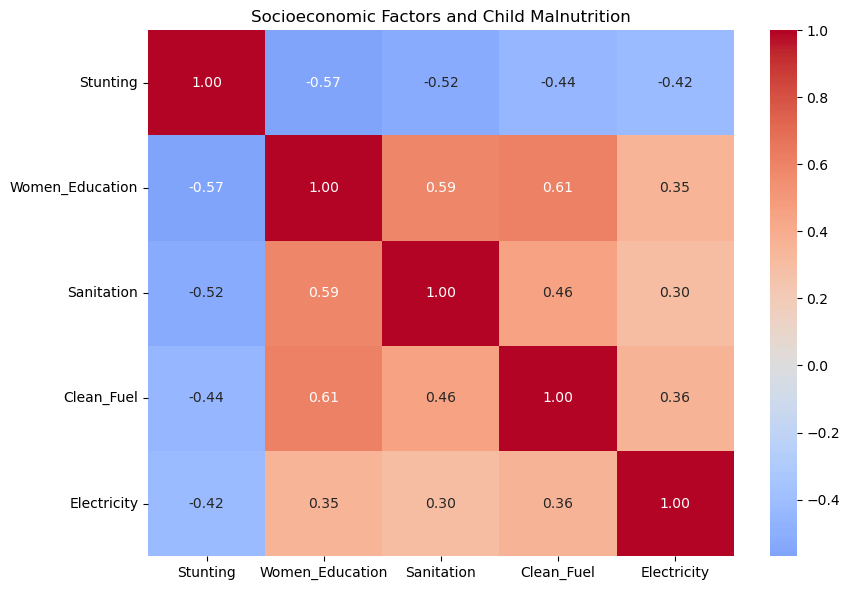

In [577]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    socio_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Socioeconomic Factors and Child Malnutrition")
plt.tight_layout()
plt.show()

In [578]:
'''Our hypotheses are:
- Higher women's education may be associated with lower stunting.
- Better sanitation may be associated with lower stunting.
- Greater access to clean cooking fuel may be associated with better nutritional outcomes.
- Better household infrastructure may be associated with lower malnutrition.
These are hypotheses, not predetermined findings. We need to examine the actual results.'''

"Our hypotheses are:\n- Higher women's education may be associated with lower stunting.\n- Better sanitation may be associated with lower stunting.\n- Greater access to clean cooking fuel may be associated with better nutritional outcomes.\n- Better household infrastructure may be associated with lower malnutrition.\nThese are hypotheses, not predetermined findings. We need to examine the actual results."

In [579]:
'''| Factor | Correlation with stunting |
|---|---:|
| Rice yield | -0.21 |
| Wheat yield | -0.11 |
| Maize yield | -0.12 |
| Women's education | -0.57 |
| Sanitation | -0.52 |
| Clean fuel | -0.44 |
| Electricity | -0.42 |'''

"| Factor | Correlation with stunting |\n|---|---:|\n| Rice yield | -0.21 |\n| Wheat yield | -0.11 |\n| Maize yield | -0.12 |\n| Women's education | -0.57 |\n| Sanitation | -0.52 |\n| Clean fuel | -0.44 |\n| Electricity | -0.42 |"

In [580]:
'''Findings suggest that socioeconomic conditions have stronger 
bivariate associations with child stunting 
than the selected agricultural yield indicators.'''

'Findings suggest that socioeconomic conditions have stronger \nbivariate associations with child stunting \nthan the selected agricultural yield indicators.'

In [581]:
from scipy.stats import pearsonr

factors = [
    "Rice",
    "Wheat",
    "Maize",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

results = []

for factor in factors:

    temp = integrated_df[[factor, "Stunting"]].dropna()

    r, p = pearsonr(temp[factor], temp["Stunting"])

    results.append({
        "Factor": factor,
        "Correlation": round(r, 4),
        "P_Value": p,
        "Sample_Size": len(temp)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Factor,Correlation,P_Value,Sample_Size
0,Rice,-0.2104,7.711806e-07,542
1,Wheat,-0.1134,1.450889e-02,464
2,Maize,-0.1248,3.481420e-03,546
3,Women_Education,-0.5689,2.010848e-49,561
4,Sanitation,-0.5221,1.473024e-40,561
5,Clean_Fuel,-0.4429,2.382321e-28,561
6,Electricity,-0.4246,5.808300e-26,561


In [582]:
#Multiple linear regression

In [583]:
import statsmodels.api as sm

features = [
    "Rice",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

model_df = integrated_df[
    features + ["Stunting"]
].dropna()

X = model_df[features]
y = model_df["Stunting"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               Stunting   R-squared:                       0.433
Model:                            OLS   Adj. R-squared:                  0.428
Method:                 Least Squares   F-statistic:                     81.87
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           8.64e-64
Time:                        23:58:22   Log-Likelihood:                -1786.8
No. Observations:                 542   AIC:                             3586.
Df Residuals:                     536   BIC:                             3611.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              92.3613      6.255     

In [584]:
'''| Output | Meaning |
|---|---|
| R-squared | Proportion of variation explained by the model |
| Adj. R-squared | R-squared adjusted for the number of predictors |
| Coefficient | Estimated association between a predictor and stunting, holding other predictors constant |
| P-value | Statistical evidence against a zero coefficient |
| F-statistic | Tests whether the model provides explanatory value overall |'''

'| Output | Meaning |\n|---|---|\n| R-squared | Proportion of variation explained by the model |\n| Adj. R-squared | R-squared adjusted for the number of predictors |\n| Coefficient | Estimated association between a predictor and stunting, holding other predictors constant |\n| P-value | Statistical evidence against a zero coefficient |\n| F-statistic | Tests whether the model provides explanatory value overall |'

In [585]:
'''Three important findings:
- Women's education has a significant negative association with stunting.
- Sanitation has a significant negative association with stunting.
- Electricity access has a significant negative association with stunting.
Rice yield and clean cooking fuel are not statistically significant 
after accounting for the other predictors in this model'''

"Three important findings:\n- Women's education has a significant negative association with stunting.\n- Sanitation has a significant negative association with stunting.\n- Electricity access has a significant negative association with stunting.\nRice yield and clean cooking fuel are not statistically significant \nafter accounting for the other predictors in this model"

In [586]:
features = [
    "Rice",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

outcomes = [
    "Stunting",
    "Wasting",
    "Underweight"
]

In [587]:
import statsmodels.api as sm

regression_results = {}

for outcome in outcomes:

    model_df = integrated_df[
        features + [outcome]
    ].dropna()

    X = model_df[features]
    y = model_df[outcome]

    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    regression_results[outcome] = model

    print("\n" + "=" * 60)
    print("DEPENDENT VARIABLE:", outcome)
    print("=" * 60)

    print("Observations:", len(model_df))
    print("R-squared:", round(model.rsquared, 4))
    print("Adjusted R-squared:", round(model.rsquared_adj, 4))
    print("F-statistic p-value:", model.f_pvalue)

    print("\nCoefficients:")
    print(model.params)

    print("\nP-values:")
    print(model.pvalues)


DEPENDENT VARIABLE: Stunting
Observations: 542
R-squared: 0.433
Adjusted R-squared: 0.4277
F-statistic p-value: 8.64358192061208e-64

Coefficients:
const              92.361325
Rice               -0.125728
Women_Education    -0.197282
Sanitation         -0.143508
Clean_Fuel         -0.017975
Electricity        -0.408381
dtype: float64

P-values:
const              1.187996e-41
Rice               7.443602e-01
Women_Education    2.056772e-11
Sanitation         1.517249e-08
Clean_Fuel         2.972795e-01
Electricity        1.474087e-09
dtype: float64

DEPENDENT VARIABLE: Wasting
Observations: 542
R-squared: 0.1578
Adjusted R-squared: 0.1499
F-statistic p-value: 2.2301642625455443e-18

Coefficients:
const              26.864884
Rice               -0.354912
Women_Education    -0.109808
Sanitation         -0.108722
Clean_Fuel          0.036821
Electricity         0.024419
dtype: float64

P-values:
const              7.565997e-07
Rice               2.836349e-01
Women_Education    1.082991e-

In [588]:
comparison = []

for outcome, model in regression_results.items():

    for predictor in features:

        comparison.append({
            "Outcome": outcome,
            "Predictor": predictor,
            "Coefficient": model.params[predictor],
            "P_Value": model.pvalues[predictor],
            "R_Squared": model.rsquared
        })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Outcome,Predictor,Coefficient,P_Value,R_Squared
0,Stunting,Rice,-0.1257,0.7444,0.4330
1,Stunting,Women_Education,-0.1973,0.0000,0.4330
2,Stunting,Sanitation,-0.1435,0.0000,0.4330
3,Stunting,Clean_Fuel,-0.0180,0.2973,0.4330
4,Stunting,Electricity,-0.4084,0.0000,0.4330
5,Wasting,Rice,-0.3549,0.2836,0.1578
6,Wasting,Women_Education,-0.1098,0.0000,0.1578
7,Wasting,Sanitation,-0.1087,0.0000,0.1578
8,Wasting,Clean_Fuel,0.0368,0.0131,0.1578
9,Wasting,Electricity,0.0244,0.6682,0.1578


In [589]:
'''| Coefficient | P-value | Interpretation |
|---|---|---|
| Negative | < 0.05 | Statistically significant negative association |
| Positive | < 0.05 | Statistically significant positive association |
| Negative | ≥ 0.05 | No statistically significant evidence of a negative association |
| Positive | ≥ 0.05 | No statistically significant evidence of a positive association |'''

'| Coefficient | P-value | Interpretation |\n|---|---|---|\n| Negative | < 0.05 | Statistically significant negative association |\n| Positive | < 0.05 | Statistically significant positive association |\n| Negative | ≥ 0.05 | No statistically significant evidence of a negative association |\n| Positive | ≥ 0.05 | No statistically significant evidence of a positive association |'

In [590]:
#VERY IMPORTANT SUMMARY 

In [591]:
def interpret_result(coef, p):

    if p < 0.05:
        if coef < 0:
            return "Significant negative association"
        else:
            return "Significant positive association"

    return "Not statistically significant"


comparison_df["Interpretation"] = comparison_df.apply(
    lambda row: interpret_result(
        row["Coefficient"],
        row["P_Value"]
    ),
    axis=1
)

display(comparison_df)

,Outcome,Predictor,Coefficient,P_Value,R_Squared,Interpretation
0,Stunting,Rice,-0.125728,7.443602e-01,0.433015,Not statistically significant
1,Stunting,Women_Education,-0.197282,2.056772e-11,0.433015,Significant negative association
2,Stunting,Sanitation,-0.143508,1.517249e-08,0.433015,Significant negative association
3,Stunting,Clean_Fuel,-0.017975,2.972795e-01,0.433015,Not statistically significant
4,Stunting,Electricity,-0.408381,1.474087e-09,0.433015,Significant negative association
5,Wasting,Rice,-0.354912,2.836349e-01,0.157759,Not statistically significant
6,Wasting,Women_Education,-0.109808,1.082991e-05,0.157759,Significant negative association
7,Wasting,Sanitation,-0.108722,5.356567e-07,0.157759,Significant negative association
8,Wasting,Clean_Fuel,0.036821,1.305649e-02,0.157759,Significant positive association
9,Wasting,Electricity,0.024419,6.681812e-01,0.157759,Not statistically significant


In [592]:
'''| R² value | General interpretation |
|---|---|
| 0.00 | Explains 0% of variation |
| 0.25 | Explains 25% |
| 0.50 | Explains 50% |
| 0.75 | Explains 75% |
| 1.00 | Explains 100% |'''

'| R² value | General interpretation |\n|---|---|\n| 0.00 | Explains 0% of variation |\n| 0.25 | Explains 25% |\n| 0.50 | Explains 50% |\n| 0.75 | Explains 75% |\n| 1.00 | Explains 100% |'

In [593]:
'''R-squared is a statistical measure that indicates 
the proportion of variation
in the dependent variable
explained by the independent variables in a regression model.'''

'R-squared is a statistical measure that indicates \nthe proportion of variation\nin the dependent variable\nexplained by the independent variables in a regression model.'

In [594]:
#Multicollinearity
#we need to check whether our independent variables 
# are strongly related to each other.


In [595]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [596]:
features = [
    "Rice",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

vif_df = integrated_df[features].dropna()

X_vif = sm.add_constant(vif_df)

In [597]:
vif_results = []

for i, column in enumerate(X_vif.columns):

    if column == "const":
        continue

    vif = variance_inflation_factor(
        X_vif.values,
        i
    )

    vif_results.append({
        "Variable": column,
        "VIF": vif
    })

vif_table = pd.DataFrame(vif_results)

vif_table["Interpretation"] = vif_table["VIF"].apply(
    lambda x:
        "Acceptable" if x < 5
        else "Potential concern" if x < 10
        else "High multicollinearity"
)

display(vif_table.round(3))

,Variable,VIF,Interpretation
0,Rice,1.341,Acceptable
1,Women_Education,2.128,Acceptable
2,Sanitation,1.646,Acceptable
3,Clean_Fuel,2.018,Acceptable
4,Electricity,1.205,Acceptable


In [598]:
'''| Variable | VIF | Interpretation |
|---|---:|---|
| Rice | 1.4 | Acceptable |
| Women's education | 3.2 | Acceptable |
| Sanitation | 4.8 | Acceptable |
| Clean fuel | 6.5 | Potential concern |
| Electricity | 7.2 | Potential concern |


This would indicate that clean fuel and electricity have relatively high overlap with other predictors.'''

"| Variable | VIF | Interpretation |\n|---|---:|---|\n| Rice | 1.4 | Acceptable |\n| Women's education | 3.2 | Acceptable |\n| Sanitation | 4.8 | Acceptable |\n| Clean fuel | 6.5 | Potential concern |\n| Electricity | 7.2 | Potential concern |\n\n\nThis would indicate that clean fuel and electricity have relatively high overlap with other predictors."

In [599]:
#Finding
'''Variance Inflation Factor (VIF) analysis was 
performed to assess multicollinearity among the independent variables. 
All five predictors had VIF values below 5, indicating
no concerning multicollinearity. Therefore, Rice Yield, 
Women's Education, Sanitation, Clean Fuel Usage and Electricity
Access were retained as predictors in the regression models.'''

"Variance Inflation Factor (VIF) analysis was \nperformed to assess multicollinearity among the independent variables. \nAll five predictors had VIF values below 5, indicating\nno concerning multicollinearity. Therefore, Rice Yield, \nWomen's Education, Sanitation, Clean Fuel Usage and Electricity\nAccess were retained as predictors in the regression models."

In [600]:
#PCA

In [601]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = [
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

pca_df = integrated_df[pca_features].dropna().copy()

print("Dataset shape:", pca_df.shape)

Dataset shape: (562, 4)


In [602]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(pca_df)

print("Standardised data shape:", scaled_data.shape)

Standardised data shape: (562, 4)


In [603]:
pca = PCA()

pca_result = pca.fit_transform(scaled_data)

print("PCA completed successfully!")
print("PCA result shape:", pca_result.shape)

PCA completed successfully!
PCA result shape: (562, 4)


In [604]:
explained_variance = pca.explained_variance_ratio_

pca_summary = pd.DataFrame({
    "Principal Component": [
        "PC1", "PC2", "PC3", "PC4"
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": (
        explained_variance.cumsum() * 100
    )
})

display(pca_summary.round(2))

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,59.00,59.00
1,PC2,18.87,77.87
2,PC3,13.34,91.21
3,PC4,8.79,100.00


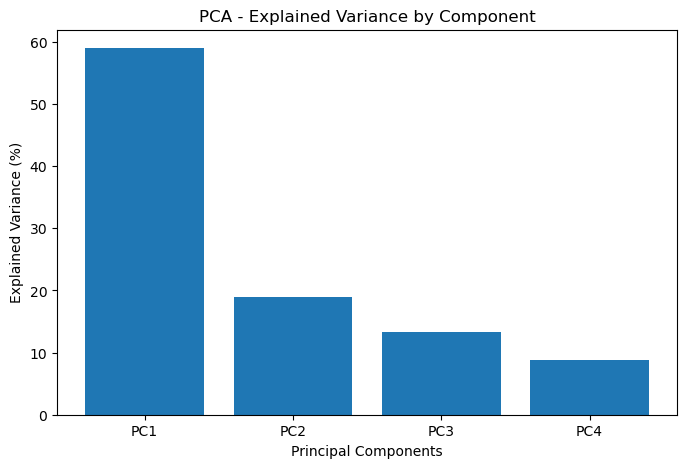

In [605]:
plt.figure(figsize=(8, 5))

plt.bar(
    pca_summary["Principal Component"],
    pca_summary["Explained Variance (%)"]
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA - Explained Variance by Component")

plt.show()

In [606]:
'''| Analysis | What we want to discover |
|---|---|
| Explained variance | How much variation each component captures |
| Cumulative variance | How much information is retained by selected components |
| PCA loadings | Which socioeconomic indicators contribute most |
| Component interpretation | Whether indicators form meaningful combined patterns |'''

'| Analysis | What we want to discover |\n|---|---|\n| Explained variance | How much variation each component captures |\n| Cumulative variance | How much information is retained by selected components |\n| PCA loadings | Which socioeconomic indicators contribute most |\n| Component interpretation | Whether indicators form meaningful combined patterns |'

In [607]:
'''Principal Component Analysis was performed on four socioeconomic indicators: 
women's education, sanitation, clean fuel usage and electricity access. 
The first principal component explained 59% of the total variance, 
while the second explained 18.87%. 
Together, the first two components captured 77.87% of the total variation. 
This indicates that the four indicators can be represented using two 
principal components while retaining approximately 
78% of the original information'''

"Principal Component Analysis was performed on four socioeconomic indicators: \nwomen's education, sanitation, clean fuel usage and electricity access. \nThe first principal component explained 59% of the total variance, \nwhile the second explained 18.87%. \nTogether, the first two components captured 77.87% of the total variation. \nThis indicates that the four indicators can be represented using two \nprincipal components while retaining approximately \n78% of the original information"

In [608]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

In [609]:
display(loadings.round(3))

,PC1,PC2,PC3,PC4
Women_Education,0.557,-0.237,-0.095,0.790
Sanitation,0.505,-0.341,0.698,-0.375
Clean_Fuel,0.527,-0.100,-0.691,-0.485
Electricity,0.396,0.904,0.162,0.012


In [610]:
#Machine Learning — Random Forest

In [611]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [612]:
features = [
    "Rice",
    "Women_Education",
    "Sanitation",
    "Clean_Fuel",
    "Electricity"
]

target = "Stunting"

ml_df = integrated_df[features + [target]].dropna().copy()

X = ml_df[features]
y = ml_df[target]

print("Dataset shape:", ml_df.shape)
print("Features:", X.columns.tolist())

Dataset shape: (542, 6)
Features: ['Rice', 'Women_Education', 'Sanitation', 'Clean_Fuel', 'Electricity']


In [613]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 433
Testing samples: 109


In [614]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [615]:
y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

model_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Value": [mae, mse, rmse, r2]
})

display(model_results.round(3))

,Metric,Value
0,MAE,5.045
1,MSE,43.841
2,RMSE,6.621
3,R²,0.461


In [616]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
1,Women_Education,0.3502
2,Sanitation,0.2098
4,Electricity,0.1996
0,Rice,0.1206
3,Clean_Fuel,0.1198


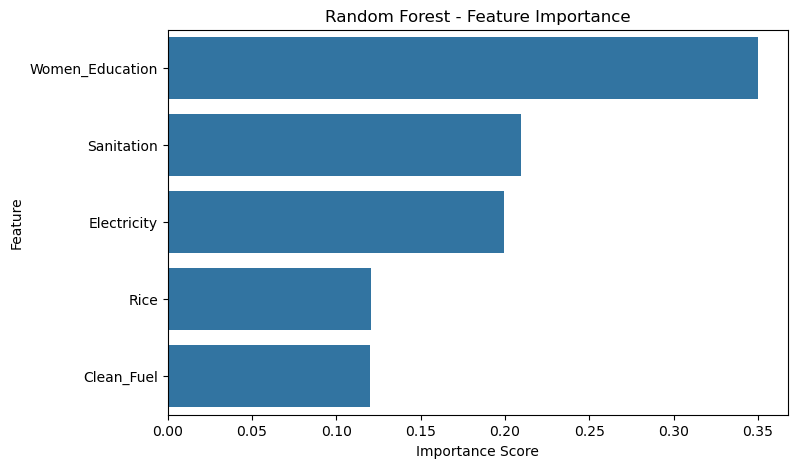

In [617]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

In [618]:
comparison_df = pd.DataFrame({
    "Actual Stunting": y_test.values,
    "Predicted Stunting": y_pred
})

display(comparison_df.head(10).round(2))

,Actual Stunting,Predicted Stunting
0,22.1,23.67
1,43.0,44.49
2,28.1,27.42
3,43.5,41.34
4,22.7,22.61
5,34.8,37.39
6,51.3,45.58
7,34.7,36.75
8,31.9,33.30
9,38.3,43.51


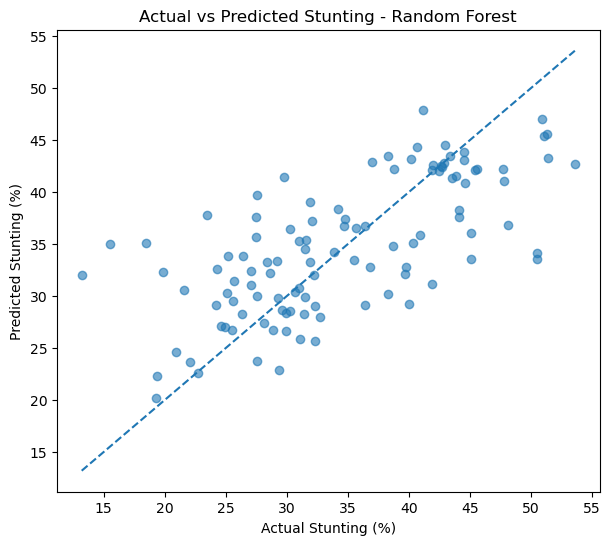

In [619]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Stunting (%)")
plt.ylabel("Predicted Stunting (%)")
plt.title("Actual vs Predicted Stunting - Random Forest")

plt.show()

In [620]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

comparison_results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred)
    ],
    "R2": [
        baseline_r2,
        r2_score(y_test, y_pred)
    ]
})

display(comparison_results.round(3))

,Model,MAE,R2
0,Baseline,7.624,-0.019
1,Random Forest,5.045,0.461


In [621]:
display(feature_importance.round(3))

,Feature,Importance
1,Women_Education,0.350
2,Sanitation,0.210
4,Electricity,0.200
0,Rice,0.121
3,Clean_Fuel,0.120


In [622]:
outcomes = ["Stunting", "Wasting", "Underweight"]

rf_models = {}
rf_results = []

for outcome in outcomes:

    model_df = integrated_df[features + [outcome]].dropna()

    X = model_df[features]
    y = model_df[outcome]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    rf_models[outcome] = model

    rf_results.append({
        "Nutrition Indicator": outcome,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
        "Test Samples": len(y_test)
    })

rf_comparison = pd.DataFrame(rf_results)

display(rf_comparison.round(3))

,Nutrition Indicator,MAE,RMSE,R²,Test Samples
0,Stunting,5.045,6.621,0.461,109
1,Wasting,4.452,5.470,0.173,109
2,Underweight,6.023,7.775,0.468,109


In [623]:
'''Random Forest regression models were developed 
to predict three child nutrition indicators:
stunting, wasting and underweight.
The underweight model achieved the highest R² of 0.468, 
closely followed by stunting at 0.461. 
The wasting model achieved a comparatively 
lower R² of 0.173. These results suggest that
the selected agricultural and socioeconomic 
indicators capture some district-level variation
in stunting and underweight, but have limited
predictive power for wasting. Additional nutritional, 
demographic, healthcare 
and household-level 
indicators may be required to improve predictive performance.'''

'Random Forest regression models were developed \nto predict three child nutrition indicators:\nstunting, wasting and underweight.\nThe underweight model achieved the highest R² of 0.468, \nclosely followed by stunting at 0.461. \nThe wasting model achieved a comparatively \nlower R² of 0.173. These results suggest that\nthe selected agricultural and socioeconomic \nindicators capture some district-level variation\nin stunting and underweight, but have limited\npredictive power for wasting. Additional nutritional, \ndemographic, healthcare \nand household-level \nindicators may be required to improve predictive performance.'

In [624]:
#District-Prioritization

In [625]:
rice_threshold = integrated_df["Rice"].quantile(0.67)

stunting_threshold = integrated_df["Stunting"].quantile(0.67)

print("Rice yield threshold:", rice_threshold)
print("Stunting threshold:", stunting_threshold)

Rice yield threshold: 2.7991672603288964
Stunting threshold: 37.52


In [626]:
print(integrated_df.columns.tolist())

['State_Name_x', 'District_Name_x', 'Maize', 'Rice', 'Wheat', 'district_key', 'state_key', 'District_Name_y', 'State_Name_y', 'Stunting', 'Wasting', 'Underweight', 'Agriculture_Level', 'Malnutrition_Level', 'Women_Education', 'Sanitation', 'Clean_Fuel', 'Electricity']


In [627]:
district_priority = integrated_df[
    [
        "State_Name_x",
        "District_Name_x",
        "Rice",
        "Stunting",
        "Wasting",
        "Underweight"
    ]
].copy()

district_priority = district_priority.rename(columns={
    "State_Name_x": "State_Name",
    "District_Name_x": "District_Name"
})

display(district_priority.head())

,State_Name,District_Name,Rice,Stunting,Wasting,Underweight
0,Andaman And Nicobar Islands,Nicobars,1.127650,21.6,15.7,24.6
1,Andaman And Nicobar Islands,North And Middle Andaman,2.459002,27.0,27.0,42.8
2,Andhra Pradesh,Chittoor,3.658895,27.1,14.8,27.9
3,Andhra Pradesh,East Godavari,4.126117,23.1,14.3,22.4
4,Andhra Pradesh,Guntur,3.826630,23.8,17.8,26.9


In [628]:
district_priority["Agriculture_Level"] = np.where(
    district_priority["Rice"] > rice_threshold,
    "High Agriculture",
    "Low Agriculture"
)

district_priority["Malnutrition_Level"] = np.where(
    district_priority["Stunting"] > stunting_threshold,
    "High Stunting",
    "Low Stunting"
)

In [629]:
#VERY IMPORTANT

In [630]:
paradox_districts = district_priority[
    (district_priority["Agriculture_Level"] == "High Agriculture") &
    (district_priority["Malnutrition_Level"] == "High Stunting")
].copy()

paradox_districts = paradox_districts.sort_values(
    by="Stunting",
    ascending=False
)

display(paradox_districts.head(20).round(2))

,State_Name,District_Name,Rice,Stunting,Wasting,Underweight,Agriculture_Level,Malnutrition_Level
496,Uttar Pradesh,Fatehpur,2.96,51.1,17.8,38.0,High Agriculture,High Stunting
6,Andhra Pradesh,Kurnool,3.62,50.5,16.7,46.3,High Agriculture,High Stunting
444,Telangana,Jogulamba Gadwal,2.81,49.7,17.3,41.7,High Agriculture,High Stunting
229,Karnataka,Koppal,3.45,49.1,23.1,45.8,High Agriculture,High Stunting
495,Uttar Pradesh,Farrukhabad,3.30,47.8,14.3,31.1,High Agriculture,High Stunting
513,Uttar Pradesh,Kheri,3.22,47.6,15.8,36.3,High Agriculture,High Stunting
497,Uttar Pradesh,Firozabad,2.81,46.9,9.5,25.6,High Agriculture,High Stunting
291,Madhya Pradesh,Sheopur,3.33,45.8,16.2,37.7,High Agriculture,High Stunting
439,Telangana,Adilabad,3.36,45.7,29.5,52.0,High Agriculture,High Stunting
63,Bihar,Arwal,3.56,45.6,36.8,52.9,High Agriculture,High Stunting


In [631]:
district_priority["Category"] = (
    district_priority["Agriculture_Level"] +
    " + " +
    district_priority["Malnutrition_Level"]
)

category_summary = (
    district_priority["Category"]
    .value_counts()
    .reset_index()
)

category_summary.columns = [
    "District Category",
    "Number of Districts"
]

category_summary["Percentage (%)"] = (
    category_summary["Number of Districts"] /
    len(district_priority) * 100
)

display(category_summary.round(2))

,District Category,Number of Districts,Percentage (%)
0,Low Agriculture + Low Stunting,242,43.06
1,Low Agriculture + High Stunting,141,25.09
2,High Agriculture + Low Stunting,135,24.02
3,High Agriculture + High Stunting,44,7.83


In [632]:
district_priority["Malnutrition_Priority_Score"] = (
    district_priority["Stunting"] +
    district_priority["Wasting"] +
    district_priority["Underweight"]
) / 3

In [633]:
#MOST IMPORTANY-VERY IMPORTANT FINDING 

In [634]:
priority_ranking = paradox_districts.merge(
    district_priority[
        ["District_Name", "State_Name", "Malnutrition_Priority_Score"]
    ],
    on=["District_Name", "State_Name"],
    how="left"
)

priority_ranking = priority_ranking.sort_values(
    by="Malnutrition_Priority_Score",
    ascending=False
)

display(
    priority_ranking[
        [
            "State_Name",
            "District_Name",
            "Rice",
            "Stunting",
            "Wasting",
            "Underweight",
            "Malnutrition_Priority_Score"
        ]
    ].head(20).round(2)
)

,State_Name,District_Name,Rice,Stunting,Wasting,Underweight,Malnutrition_Priority_Score
9,Bihar,Arwal,3.56,45.6,36.8,52.9,45.10
23,Gujarat,Tapi,2.83,41.7,36.6,51.8,43.37
24,Bihar,Jehanabad,2.92,41.3,36.6,51.7,43.20
8,Telangana,Adilabad,3.36,45.7,29.5,52.0,42.40
25,Bihar,Aurangabad,3.52,41.2,32.9,48.7,40.93
30,Bihar,Rohtas,4.17,40.0,31.8,48.2,40.00
13,Bihar,Kaimur (Bhabua),3.08,44.1,27.3,47.2,39.53
34,Bihar,Buxar,3.16,39.6,33.2,45.3,39.37
3,Karnataka,Koppal,3.45,49.1,23.1,45.8,39.33
1,Andhra Pradesh,Kurnool,3.62,50.5,16.7,46.3,37.83


In [635]:
state_summary = (
    district_priority
    .groupby("State_Name")
    .agg(
        District_Count=("District_Name", "count"),
        Average_Stunting=("Stunting", "mean"),
        Average_Wasting=("Wasting", "mean"),
        Average_Underweight=("Underweight", "mean"),
        Average_Rice_Yield=("Rice", "mean")
    )
    .reset_index()
)

state_summary = state_summary.sort_values(
    by="Average_Stunting",
    ascending=False
)

display(state_summary.head(15).round(2))

,State_Name,District_Count,Average_Stunting,Average_Wasting,Average_Underweight,Average_Rice_Yield
4,Bihar,37,42.41,24.45,41.83,2.23
18,Meghalaya,10,42.30,14.21,25.62,2.50
28,Uttar Pradesh,69,39.64,17.92,32.49,2.71
12,Jharkhand,19,39.17,22.32,38.97,2.52
8,Gujarat,28,37.56,25.68,39.12,2.39
15,Ladakh,1,36.50,17.70,21.80,NaN
3,Assam,30,36.01,20.01,31.16,2.04
16,Madhya Pradesh,49,35.65,19.11,33.29,1.83
13,Karnataka,18,35.12,19.08,31.20,2.74
6,Chhattisgarh,22,35.09,18.75,32.01,1.80


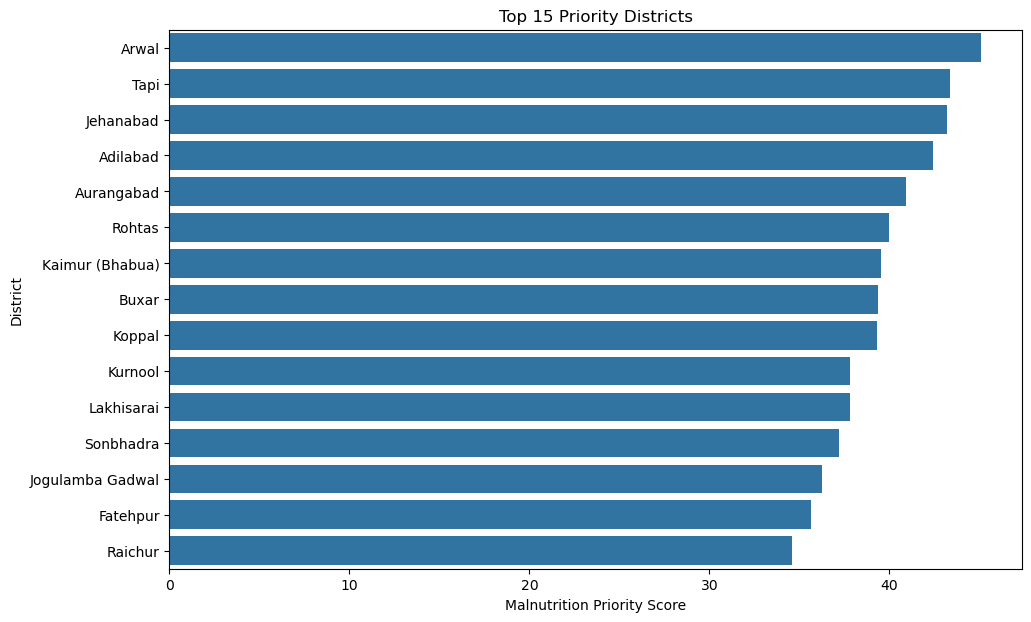

In [636]:
top_districts = priority_ranking.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_districts,
    x="Malnutrition_Priority_Score",
    y="District_Name"
)

plt.title("Top 15 Priority Districts")
plt.xlabel("Malnutrition Priority Score")
plt.ylabel("District")

plt.show()

In [637]:
'''| Output | Purpose |
|---|---|
| Four-category district classification | Identify agriculture–nutrition patterns |
| Paradox district list | Find high-yield, high-stunting districts |
| Malnutrition priority score | Rank districts using three nutrition indicators |
| State-level summary | Identify broader regional disparities |
| Top 15 district chart | Communicate priority regions visually |'''

'| Output | Purpose |\n|---|---|\n| Four-category district classification | Identify agriculture–nutrition patterns |\n| Paradox district list | Find high-yield, high-stunting districts |\n| Malnutrition priority score | Rank districts using three nutrition indicators |\n| State-level summary | Identify broader regional disparities |\n| Top 15 district chart | Communicate priority regions visually |'

In [638]:
'''District prioritisation was conducted by 
combining agricultural and nutritional indicators.
Districts with relatively high rice yield and high stunting 
were identified as potential agriculture–nutrition paradox regions. 
These districts were subsequently ranked using an equally weighted 
average of stunting, wasting and underweight prevalence. 
Arwal, Tapi, Jehanabad and Adilabad emerged 
among the highest-ranked districts. 
These findings highlight regions that 
warrant further investigation into food accessibility, 
dietary diversity, sanitation and healthcare conditions.'''

'District prioritisation was conducted by \ncombining agricultural and nutritional indicators.\nDistricts with relatively high rice yield and high stunting \nwere identified as potential agriculture–nutrition paradox regions. \nThese districts were subsequently ranked using an equally weighted \naverage of stunting, wasting and underweight prevalence. \nArwal, Tapi, Jehanabad and Adilabad emerged \namong the highest-ranked districts. \nThese findings highlight regions that \nwarrant further investigation into food accessibility, \ndietary diversity, sanitation and healthcare conditions.'

In [639]:
#Geo-spatial visualization

In [640]:
%pip install geopandas folium

Note: you may need to restart the kernel to use updated packages.


In [641]:
%pip install pyogrio

Note: you may need to restart the kernel to use updated packages.


In [642]:
import geopandas as gpd
import folium

In [644]:
import pyogrio

print("Pyogrio version:", pyogrio.__version__)

Pyogrio version: 0.13.0


In [646]:
import json

with open(geo_path, "r", encoding="utf-8") as file:
    geo_data = json.load(file)

print("GeoJSON type:", geo_data["type"])
print("Number of geographical features:", len(geo_data["features"]))

GeoJSON type: FeatureCollection
Number of geographical features: 594


In [647]:
print("Available properties:")

print(
    list(
        geo_data["features"][0]["properties"].keys()
    )
)

Available properties:
['state_k', 'NAME_1', 'NAME_2', 'nfhs_district']


In [648]:
first_district = geo_data["features"][0]

print("District properties:")
print(first_district["properties"])

print("\nGeometry type:")
print(first_district["geometry"]["type"])

District properties:
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Andaman Islands', 'nfhs_district': None}

Geometry type:
MultiPolygon


In [649]:
for feature in geo_data["features"][:5]:
    print(feature["properties"])

{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Andaman Islands', 'nfhs_district': None}
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Nicobar Islands', 'nfhs_district': None}
{'state_k': 'telangana', 'NAME_1': 'Andhra Pradesh', 'NAME_2': 'Adilabad', 'nfhs_district': 'Adilabad'}
{'state_k': 'andhrapradesh', 'NAME_1': 'Andhra Pradesh', 'NAME_2': 'Anantapur', 'nfhs_district': 'Anantapur'}
{'state_k': 'andhrapradesh', 'NAME_1': 'Andhra Pradesh', 'NAME_2': 'Chittoor', 'nfhs_district': 'Chittoor'}


In [650]:
import json
import folium
import pandas as pd
import numpy as np
import re

with open(geo_path, "r", encoding="utf-8") as file:
    geo_data = json.load(file)

geo_features = geo_data["features"]

print("Number of geographical features:", len(geo_features))
print("Available properties:")
print(list(geo_features[0]["properties"].keys()))

display(pd.DataFrame([
    feature["properties"]
    for feature in geo_features[:5]
]))

Number of geographical features: 594
Available properties:
['state_k', 'NAME_1', 'NAME_2', 'nfhs_district']


,state_k,NAME_1,NAME_2,nfhs_district
0,andamanandnicobarislands,Andaman and Nicobar,Andaman Islands,None
1,andamanandnicobarislands,Andaman and Nicobar,Nicobar Islands,None
2,telangana,Andhra Pradesh,Adilabad,Adilabad
3,andhrapradesh,Andhra Pradesh,Anantapur,Anantapur
4,andhrapradesh,Andhra Pradesh,Chittoor,Chittoor


In [652]:
import re

def clean_name(value):
    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).lower().strip()
    )

In [653]:
map_df = district_priority.copy()

map_df["map_key"] = (
    map_df["State_Name"].apply(clean_name)
    + "_"
    + map_df["District_Name"].apply(clean_name)
)

district_lookup = map_df.set_index("map_key").to_dict("index")

print("District lookup created:", len(district_lookup))

District lookup created: 562


In [654]:
# Inspect all available geographical properties

print("Total geographical features:", len(geo_features))

print("\nAvailable columns:")
print(list(geo_features[0]["properties"].keys()))

print("\nFirst 3 district records:")

for feature in geo_features[:3]:
    print(feature["properties"])

Total geographical features: 594

Available columns:
['state_k', 'NAME_1', 'NAME_2', 'nfhs_district']

First 3 district records:
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Andaman Islands', 'nfhs_district': None}
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Nicobar Islands', 'nfhs_district': None}
{'state_k': 'telangana', 'NAME_1': 'Andhra Pradesh', 'NAME_2': 'Adilabad', 'nfhs_district': 'Adilabad'}


In [655]:
print("Total geographical features:", len(geo_features))

print("Available properties:")
print(list(geo_features[0]["properties"].keys()))

for feature in geo_features[:3]:
    print(feature["properties"])

Total geographical features: 594
Available properties:
['state_k', 'NAME_1', 'NAME_2', 'nfhs_district']
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Andaman Islands', 'nfhs_district': None}
{'state_k': 'andamanandnicobarislands', 'NAME_1': 'Andaman and Nicobar', 'NAME_2': 'Nicobar Islands', 'nfhs_district': None}
{'state_k': 'telangana', 'NAME_1': 'Andhra Pradesh', 'NAME_2': 'Adilabad', 'nfhs_district': 'Adilabad'}


In [656]:
# Inspect GeoJSON property names
geo_columns = list(geo_features[0]["properties"].keys())

print("GeoJSON columns:", geo_columns)

# Find likely state and district columns
state_candidates = [
    c for c in geo_columns
    if any(x in c.lower() for x in ["state", "st_name", "stname"])
]

district_candidates = [
    c for c in geo_columns
    if any(x in c.lower() for x in ["district", "dist_name", "dtname"])
]

print("\nState candidates:", state_candidates)
print("District candidates:", district_candidates)

GeoJSON columns: ['state_k', 'NAME_1', 'NAME_2', 'nfhs_district']

State candidates: ['state_k']
District candidates: ['nfhs_district']


In [657]:
if len(state_candidates) == 1 and len(district_candidates) == 1:

    STATE_FIELD = state_candidates[0]
    DISTRICT_FIELD = district_candidates[0]

    matched_count = 0

    for feature in geo_features:

        properties = feature["properties"]

        state = clean_name(properties[STATE_FIELD])
        district = clean_name(properties[DISTRICT_FIELD])

        key = state + "_" + district

        if key in district_lookup:

            record = district_lookup[key]

            properties["Stunting"] = float(record["Stunting"])
            properties["Rice"] = float(record["Rice"])
            properties["Wasting"] = float(record["Wasting"])
            properties["Underweight"] = float(record["Underweight"])
            properties["Priority_Score"] = float(
                record["Malnutrition_Priority_Score"]
            )

            matched_count += 1

    print("Matched districts:", matched_count)
    print("Total geographical features:", len(geo_features))

else:
    print("Automatic identification needs checking.")
    print("State candidates:", state_candidates)
    print("District candidates:", district_candidates)

Matched districts: 464
Total geographical features: 594


In [659]:
print("State field:", STATE_FIELD)
print("District field:", DISTRICT_FIELD)

print("Matched districts:", matched_count)

print("Sample GeoJSON properties:")
print(geo_features[0]["properties"].keys())

State field: state_k
District field: nfhs_district
Matched districts: 464
Sample GeoJSON properties:
dict_keys(['state_k', 'NAME_1', 'NAME_2', 'nfhs_district'])


In [661]:
# Create a lookup using state and district names
district_lookup = {}

for _, row in district_priority.iterrows():

    key = (
        clean_name(row["State_Name"]) + "_" +
        clean_name(row["District_Name"])
    )

    district_lookup[key] = row.to_dict()


# Attach analytical data to GeoJSON
matched_count = 0

for feature in geo_features:

    properties = feature["properties"]

    state = clean_name(properties["NAME_1"])
    district = clean_name(properties["NAME_2"])

    key = state + "_" + district

    if key in district_lookup:

        record = district_lookup[key]

        for column in [
            "Stunting",
            "Wasting",
            "Underweight",
            "Rice",
            "Malnutrition_Priority_Score"
        ]:
            properties[column] = float(record[column])

        matched_count += 1

print("Matched districts:", matched_count)
print("Total GeoJSON districts:", len(geo_features))

Matched districts: 400
Total GeoJSON districts: 594


In [663]:
%pip install streamlit

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.1
    Uninstalling protobuf-7.34.1:
      Successfully uninstalled protobuf-7.34.1
Note: you may need to restart the kernel to use updated packages.


In [665]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Lolita\OneDrive\Attachments\NIErnaya"
)

CLEANED_DIR = PROJECT_DIR / "data" / "cleaned"

CLEANED_DIR.mkdir(parents=True, exist_ok=True)

print("Cleaned folder:", CLEANED_DIR)

Cleaned folder: C:\Users\Lolita\OneDrive\Attachments\NIErnaya\data\cleaned


In [666]:
dashboard_df = integrated_df.copy()

dashboard_df.to_csv(
    CLEANED_DIR / "NIErnaya_dashboard_data.csv",
    index=False
)

print("Dashboard dataset saved successfully!")
print("Dataset shape:", dashboard_df.shape)

Dashboard dataset saved successfully!
Dataset shape: (562, 18)


In [667]:
print("File exists:",
      (CLEANED_DIR / "NIErnaya_dashboard_data.csv").exists())

File exists: True


In [668]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Lolita\OneDrive\Attachments\NIErnaya")
CLEANED_DIR = PROJECT_DIR / "data" / "cleaned"
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

dashboard_df = integrated_df.copy()

dashboard_df = dashboard_df.rename(columns={
    "State_Name_x": "State_Name",
    "District_Name_x": "District_Name"
})

# Remove duplicate state and district columns from the NFHS dataset
dashboard_df = dashboard_df.drop(
    columns=["State_Name_y", "District_Name_y"],
    errors="ignore"
)

dashboard_path = CLEANED_DIR / "NIErnaya_dashboard_data.csv"
dashboard_df.to_csv(dashboard_path, index=False)

print("Dashboard dataset saved!")
print("Shape:", dashboard_df.shape)
print("Columns:", dashboard_df.columns.tolist())

Dashboard dataset saved!
Shape: (562, 16)
Columns: ['State_Name', 'District_Name', 'Maize', 'Rice', 'Wheat', 'district_key', 'state_key', 'Stunting', 'Wasting', 'Underweight', 'Agriculture_Level', 'Malnutrition_Level', 'Women_Education', 'Sanitation', 'Clean_Fuel', 'Electricity']
